# NARS vs LLM baselines
Every system reads the same 70B-extracted facts. Set the dataset, split, hops and sample size in **Settings**, then run NARS, the baselines, or both. The **Final report** compares whatever has been run.

**Tune on `SPLIT = "dev"`, report on `SPLIT = "test"`.** The dev sets (`python pipeline.py --dataset MuSiQue --split dev --hops 2`) share no question or paragraph with the test sets, so changes to ONA.py tried on dev cannot leak into test results. Look at `error_nars.txt` of dev runs only; run the test split once ONA.py is frozen.

Each run writes `runs/<dataset>[_dev]_2hop_100q_seed0[_<options>]/`: `nars.jsonl`, `baselines.jsonl`, `error_nars.txt`, `report.png`.

In [1]:
# ── Settings: change these, then run the cells you need ──────────────────────────────────────────
import importlib
import json
import os
import pickle
import random
import re
import threading
import time
import unicodedata
import urllib.request
from collections import Counter
from concurrent.futures import ThreadPoolExecutor, as_completed

import matplotlib.pyplot as plt
from openai import OpenAI
from prettytable import PrettyTable

import ONA

importlib.reload(ONA)  # pick up edits to ONA.py without restarting

from keys import deepinfra_key
API_KEY = deepinfra_key()  # $DEEPINFRA_API_KEY or the git-ignored .deepinfra_key
DATASET = "2Wiki"   # "MuSiQue", "HotpotQA" or "2Wiki"
SPLIT = "test"         # "dev" to try ONA.py changes, "test" for the reported results (never tune on test)
HOPS = 2              # MuSiQue has 2, 3 and 4 hops; HotpotQA and 2Wiki only 2
N_QUESTIONS = 100     # random sample size
DISTRACTORS = False   # True: every system reads the facts of ALL paragraphs (supporting + distractors, in the
                      # dataset's order) instead of only the supporting ones. Needs pipeline.py --distractors first.
SEED = 0              # same seed -> same questions every run
WORKERS = 8           # questions processed at the same time
ONA_PATH = "/Users/mina/Developer/OpenNARS-for-Applications/NAR"
JUDGE_MODEL = "Qwen/Qwen2.5-72B-Instruct"  # for the judge metric; not one of the systems, so nobody grades itself
NARS_MODEL = "meta-llama/Llama-3.3-70B-Instruct-Turbo"  # turns the facts into triples and rules for ONA
NARS_MODEL = "deepseek-ai/DeepSeek-V3"
# ONA.py options (all off = the pipeline of the final test): plan the hops first, vote over up to 3 rule sets,
# and also state each triple under its relation's general form ("youngest_son_of" -> "son_of" -> "child_of").
# Each run's folder name records the options that are on.
ONA_OPTIONS = {"plan": True, "votes": 3, "merge_relations": True}

BASELINES = [  # answer directly from the same facts; small to large, all served under their own name
    "google/gemma-3-4b-it",
    "meta-llama/Meta-Llama-3.1-8B-Instruct-Turbo",
    "mistralai/Mistral-Nemo-Instruct-2407",               # 12B
    "google/gemma-3-12b-it",
    "microsoft/phi-4",                                    # 14B
    "mistralai/Mistral-Small-3.2-24B-Instruct-2506",
    "google/gemma-3-27b-it",
    "google/gemma-4-31B-it",
    "meta-llama/Llama-3.3-70B-Instruct-Turbo",
    "Qwen/Qwen3-Next-80B-A3B-Instruct",
    "Qwen/Qwen3-235B-A22B-Instruct-2507",
    "deepseek-ai/DeepSeek-V3",
]

client = OpenAI(api_key=API_KEY, base_url="https://api.deepinfra.com/v1/openai", max_retries=2, timeout=60)


def check_models(models):
    """DeepInfra silently answers retired models with another one (Llama-3.2-1B came back as gemma-4-31B).
    One tiny request per model; stop if any model is served under another name."""
    def served(m):
        try:
            return client.chat.completions.create(model=m, max_tokens=1, messages=[{"role": "user", "content": "Hi"}]).model
        except Exception as error:
            return f"error: {type(error).__name__}"
    with ThreadPoolExecutor(8) as executor:
        swapped = {m: s for m, s in zip(models, executor.map(served, models)) if s != m}
    assert not swapped, f"These models are not served as requested: {swapped}"


check_models([NARS_MODEL, JUDGE_MODEL, *BASELINES])


def label(model):
    return model.split("/")[-1].replace("Meta-", "").replace("-Instruct-Turbo", "").replace("-Instruct", "").replace("-it", "")


def load_prices():
    """Live DeepInfra prices, USD per million tokens (input, output). Tries 3 times; {} if all fail."""
    for attempt in range(3):
        try:
            with urllib.request.urlopen("https://api.deepinfra.com/models/list", timeout=20) as response:
                return {m["model_name"]: (m["pricing"]["cents_per_input_token"] * 1e4, m["pricing"]["cents_per_output_token"] * 1e4)
                        for m in json.load(response) if (m.get("pricing") or {}).get("type") == "tokens"}
        except Exception as error:
            print(f"Price lookup failed ({type(error).__name__}), attempt {attempt + 1}/3")
            time.sleep(2)
    return {}


PRICES = load_prices()


def cost(input_tokens, output_tokens, model):
    if model not in PRICES:  # the lookup failed earlier, or a new model: try again
        PRICES.update(load_prices())
    if model not in PRICES:
        print(f"   ! no price for {model}: its cost counts as $0")
        PRICES[model] = (0, 0)
    price = PRICES[model]
    return (input_tokens * price[0] + output_tokens * price[1]) / 1_000_000


for m in [NARS_MODEL, JUDGE_MODEL, *BASELINES]:  # warn now, not after the run
    if m not in PRICES:
        print(f"Warning: no price for {m}; costs will be $0 until the lookup works.")


# ── Scoring ──────────────────────────────────────────────────────────────────────────────────────
def normalize(text):
    text = unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().casefold()
    return re.sub(r"[^a-z0-9]", "", re.sub(r"\b(a|an|the)\b", " ", text))


def lenient(answer, golds):
    """Answer and a gold answer contain each other, the shorter covering at least half of the longer."""
    a = normalize(answer or "")
    for g in map(normalize, golds):
        short, long_ = sorted((a, g), key=len)
        if short and short in long_ and 2 * len(short) >= len(long_):
            return True
    return False


def exact(answer, golds):
    return any(normalize(answer or "") == normalize(g) for g in golds)


JUDGE_PROMPT = """You grade answers to a question. Be strict.

Question: {question}
Gold answer: {gold}
Model answer: {answer}

The model answer is correct ONLY if it names the same entity, date, number or place as the gold answer.
Different wording, a full name, or extra detail around the same thing is fine:
  "Philip Mountbatten" for "Prince Philip" -> yes
  "12,000 people" for "12,000" -> yes
  "4 June 1990" for "1990" -> yes
It is WRONG if it names something else, even something related: a part of the gold answer, a larger thing that
contains it, a person connected to it, or a vaguer or partial answer:
  "Battle of Hastings" for "Norman Conquest" -> no   (a part, not the same thing)
  "Henry VIII" for "Edward VI" -> no                 (a related person)
  "Europe" for "France" -> no                        (broader)
  "200 km" for "200 km south of Paris" -> no         (partial)
  "The text does not say" -> no                      (no answer)
Reply with only yes or no."""


METRICS = ["exact", "lenient", "judge"]


def metrics(q, answer):
    """The three accuracy metrics for one answer. exact: same text after normalizing. lenient: one contains the
    other. judge: lenient, or else the judge model says it is the same thing (only asked when lenient fails)."""
    g = golds(q)
    result = {"exact": exact(answer, g), "lenient": lenient(answer, g), "judge_cost": 0.0}
    result["judge"] = result["lenient"]
    if answer and not result["lenient"]:
        try:
            response = client.chat.completions.create(model=JUDGE_MODEL, temperature=0, max_tokens=3, messages=[{
                "role": "user", "content": JUDGE_PROMPT.format(question=q["question"], gold=q["answer"], answer=answer)}])
            result["judge"] = (response.choices[0].message.content or "").strip().lower().startswith("yes")
            result["judge_cost"] = cost(response.usage.prompt_tokens or 0, response.usage.completion_tokens or 0, JUDGE_MODEL)
        except Exception as error:  # judge unavailable: keep the lenient verdict
            print(f"   ! judge failed ({type(error).__name__}), using the lenient match")
    return result


def so_far(records):
    """Running score on all three metrics, e.g. 'E 30  L 41  J 45'."""
    return "  ".join(f"{m[0].upper()} {sum(r[m] for r in records)}" for m in METRICS)


def mentions(text, golds):
    t = normalize(text)
    heads = [re.split(r"[,(]", g)[0] for g in golds]
    return any(g and t and (g in t or (t in g and 2 * len(t) >= len(g))) for g in map(normalize, [*golds, *heads]))


def golds(q):
    return [q["answer"], *(q.get("gold_answers") or [])]


def paragraphs(q):
    """The paragraphs every system reads: the supporting ones, or with DISTRACTORS all of them."""
    return [p for p in (q["context"] if DISTRACTORS else q["supporting"]) if p["facts"]]


def facts(q):
    return [f for p in paragraphs(q) for f in p["facts"]]


# ── Audits ───────────────────────────────────────────────────────────────────────────────────────
# ONA.py's automatic rule repairs, counted per question. auto_hop and pruned_unlinked change what the rule asks
# (a search for a missing link, or dropping conditions), so watch how often they fire and how often they are right.
REPAIRS = ["literal_answer", "embedded_var", "inverse_relation", "bridged_constant", "pruned_unlinked", "auto_hop"]


def repair_audit(nars_records):
    """How often each ONA auto-repair fired, and NARS's judge accuracy with and without it."""
    table = PrettyTable(["Auto-repair", "Questions", "Judge right when used", "Judge right otherwise"])
    for repair in REPAIRS:
        used = [r for r in nars_records if r.get("auto_repairs", {}).get(repair)]
        other = [r for r in nars_records if not r.get("auto_repairs", {}).get(repair)]
        pct = lambda rs: f"{sum(r['judge'] for r in rs)}/{len(rs)}" + (f" = {100 * sum(r['judge'] for r in rs) / len(rs):.0f}%" if rs else "")
        table.add_row([repair, len(used), pct(used), pct(other)])
    none = [r for r in nars_records if not any(r.get("auto_repairs", {}).values())]
    print(f"ONA AUTO-REPAIRS (a question can use several; {len(none)} questions used none, "
          f"judge right on {sum(r['judge'] for r in none)} of them)")
    print(table)


STOPWORDS = {"the", "and", "for", "with", "who", "what", "which", "when", "where", "was", "did", "does", "from", "film"}


def from_question(rules, question):
    """True if every rule starts from entities named in the question: each rule has a constant, and every constant
    shares a word with the question. False means the 70B filled in a hop itself (e.g. "madina_lake formed_in ?C"
    for "When did the Leone brothers start their band?") or a rule has no anchor at all, so the answer is not
    NARS chaining from the question."""
    q_words = set(re.findall(r"[a-z0-9]{3,}", normalize_words(question))) - STOPWORDS
    for rule in rules:
        constants = [x for c in rule["conditions"] for x in (c[0], c[2]) if not x.startswith("?")]
        if not constants or not all(set(re.findall(r"[a-z0-9]{3,}", normalize_words(x))) & q_words for x in constants):
            return False
    return bool(rules)


def normalize_words(text):
    return unicodedata.normalize("NFKD", str(text)).encode("ascii", "ignore").decode().lower().replace("_", " ")


# ── Questions, run folder and the shared run loop ────────────────────────────────────────────────
with open(f"runs/{DATASET}_{SPLIT}_entity.pkl", "rb") as f:
    questions = pickle.load(f)
pool = [i for i, q in enumerate(questions) if q["hops"] == HOPS]
INDICES = sorted(random.Random(SEED).sample(pool, min(N_QUESTIONS, len(pool))))
OPTIONS_TAG = "_".join(k if v is True else f"{k}{v}" for k, v in ONA_OPTIONS.items()
                       if v is True or (type(v) is int and v > 1))  # e.g. "plan_votes3_merge_relations"
RUN_DIR = (f"runs/{DATASET}{'_dev' if SPLIT == 'dev' else ''}_{HOPS}hop_{len(INDICES)}q_seed{SEED}"
           + (f"_{OPTIONS_TAG}" if OPTIONS_TAG else "") + ("_distractors" if DISTRACTORS else ""))  # NARS and baselines save here
missing = [i for i in INDICES if DISTRACTORS and "context" not in questions[i]]
assert not missing, (f"{len(missing)} questions have no distractor facts: run  python pipeline.py --dataset {DATASET} "
                     f"--split {SPLIT} --hops {HOPS} --distractors {N_QUESTIONS}")
os.makedirs(RUN_DIR, exist_ok=True)


def run_all(task, out_file, show):
    """Run task(index) on every question in parallel. Each record is saved and printed as soon as it finishes."""
    path, records, start = f"{RUN_DIR}/{out_file}", [], time.time()
    open(path, "w").close()  # start this file fresh
    with ThreadPoolExecutor(WORKERS) as executor:
        futures = [executor.submit(task, i) for i in INDICES]
        for done, future in enumerate(as_completed(futures), 1):
            record = future.result()
            records.append(record)
            with open(path, "a") as f:
                f.write(json.dumps(record, ensure_ascii=False, default=str) + "\n")
            print(f"[{done:>3}/{len(INDICES)}, {len(INDICES) - done:>3} left] Q{record['index']:<4} gold: {record['gold'][:30]}"
                  f"\n      {show(record, records)}"
                  f"\n      spent ${sum(r['cost'] + r['judge_cost'] for r in records):.4f}   {time.time() - start:.0f}s")
    return sorted(records, key=lambda r: r["index"])


print(f"{len(INDICES)} random {DATASET} {SPLIT} {HOPS}-hop questions (of {len(pool)}). ONA options: {ONA_OPTIONS}. "
      f"Results go to {RUN_DIR}/")

100 random 2Wiki test 2-hop questions (of 149). ONA options: {'plan': True, 'votes': 3, 'merge_relations': True}. Results go to runs/2Wiki_2hop_100q_seed0_plan_votes3_merge_relations/


## Run NARS

In [2]:
# ── NARS: the 70B translates the facts into triples and rules, ONA reasons ───────────────────────
def lost_at(q, ona, answer, correct):
    """The first NARS step after which the gold answer is gone."""
    g = golds(q)
    if correct:
        return "correct"
    if not any(mentions(f, g) for f in facts(q)):
        return "lost in facts"
    if not ona.last_triples:
        return "API error"
    if not any(mentions(x, g) for t in ona.last_triples for x in (t["subject"], t["object"])):
        return "lost in triples"
    if not ona.last_rules:
        return "no valid rule"
    if not any(mentions(ona.names.get(c, c), g) for c in ona.candidates):
        return "rules miss the answer"
    return "ONA did not derive it" if answer is None else "picked wrong answer"


ERROR_FILE = f"{RUN_DIR}/error_nars.txt"  # every NARS step of each failed question, rewritten on every run
error_lock = threading.Lock()  # questions run in parallel; one writes to the file at a time


def step_name(call):
    """Which prompt an LLM call answered: TRIPLES, TRIPLE_REPAIR, ALIASES, RULES or REPAIR."""
    last = call["messages"][-1]["content"]
    for name, start in [("TRIPLE_REPAIR", "These names and values"), ("REPAIR", "Those rules do not work"),
                        ("ALIASES", "Group the names"), ("RULES", "Write rules"), ("TRIPLES", "Convert the facts")]:
        if last.startswith(start):
            return name
    return "LLM"


def write_failure(r, t):
    """Append one failed question to error_nars.txt: its facts and everything NARS generated from them."""
    line = "=" * 100
    with error_lock, open(ERROR_FILE, "a") as f:
        q = questions[r["index"]]
        f.write(f"\n{line}\nQ{r['index']}: {q['question']}\nGold: {' / '.join(dict.fromkeys(golds(q)))}\n"
                f"NARS answer: {r['answer']}\nLost at: {r['lost_at']}\nAuto-repairs: {r['auto_repairs'] or 'none'}\n")
        if t.get("error"):
            f.write(f"Error: {t['error']}\n")
        if t.get("plan"):
            f.write("\n-- Hop plan (the LLM's, from the question alone)\n" + "".join(f"   {h}\n" for h in t["plan"].splitlines()))
        if t.get("votes") and len(t["votes"]) > 1:
            f.write(f"-- Answers of the rule sets voted on: {t['votes']}\n")
        if q.get("decomposition"):
            f.write("\n-- Gold decomposition\n" + "".join(f"   {d['question']} -> {d['answer']}\n" for d in q["decomposition"]))
        f.write("\n-- Facts\n")
        for p in paragraphs(q):
            f.write(f"   [{p['title']}]\n" + "".join(f"   - {x}\n" for x in p["facts"]))
        f.write("\n-- LLM generations, in order\n")
        for call in t.get("calls", []):
            f.write(f"   [{step_name(call)}] {call.get('response', 'ERROR: ' + str(call.get('error')))}\n")
        f.write("\n-- Triples after aliases and inverses\n")
        f.write("".join(f"   {x['subject']} | {x['relation']} | {x['object']}{'   (inverse)' if x.get('inverse') else ''}\n"
                        for x in t.get("triples", [])))
        if t.get("relation_groups"):
            f.write(f"\n-- Relations also stated in a general form: {t['relation_groups']}\n")
        merged = {a: c for a, c in t.get("aliases", {}).items() if a != c}
        f.write(f"\n-- Aliases merged: {json.dumps(merged, ensure_ascii=False) if merged else 'none'}\n")
        f.write(f"-- Names missing from every triple: {t.get('missing_terms') or 'none'}\n")
        f.write("\n-- Rule attempts (raw JSON, then the problems sent back)\n")
        for k, (raw, problems) in enumerate(t.get("rule_attempts", []), 1):
            f.write(f"   attempt {k}: {raw.strip()}\n" + "".join(f"      problem: {p}\n" for p in problems))
        f.write(f"\n-- Final rules (answer_type {t.get('answer_type')}, start from the question: {r['from_question']})\n"
                f"{json.dumps(r['rules'], ensure_ascii=False)}\n")
        f.write(f"-- Candidates the rules bind: {t.get('candidates') or 'none'}\n")
        f.write(f"\n-- Narsese sent to ONA\n{t.get('narsese') or '(none)'}\n")
        f.write(f"-- ONA output\n{(t.get('output') or '(none)').strip()}\n")


def run_nars(index):
    q = questions[index]
    ona = ONA.OnaReasoner(client, model=NARS_MODEL, **ONA_OPTIONS)
    answer, error = None, None
    try:
        answer = ona.solve([p["facts"] for p in paragraphs(q)], q["question"], ONA_PATH)
    except Exception as e:  # e.g. an API timeout
        error = f"{type(e).__name__}: {e}"
        print(f"   ! Q{index}: {str(e)[:80]}")
    trace = {"calls": ona.request_log, "triples": ona.last_triples, "aliases": ona.aliases,
             "missing_terms": ona.missing_terms, "rule_attempts": ona.rule_attempts,
             "answer_type": ona.answer_type, "candidates": [ona.names.get(c, c) for c in ona.candidates],
             "narsese": ona.last_narsese, "output": ona.last_output, "error": error, "plan": ona.plan_text,
             "relation_groups": ona.relation_groups, "votes": [s["answer"] for s in ona.samples]}
    m = metrics(q, answer)
    record = {"index": index, "question": q["question"], "gold": q["answer"], "answer": answer, **m,
              "lost_at": lost_at(q, ona, answer, m["judge"]), "rules": ona.last_rules, "auto_repairs": dict(ona.auto_repairs),
              "from_question": from_question(ona.last_rules, q["question"]),
              "ona_top": ona.ona_top, "ona_top_lenient": lenient(ona.ona_top, golds(q)),
              "votes": [s["answer"] for s in ona.samples],
              "cost": cost(ona.usage["input_tokens"], ona.usage["output_tokens"], NARS_MODEL)}
    if not record["judge"]:
        write_failure(record, trace)  # written now, so the file fills up while the run goes
    return record


def show_nars(r, records):
    why = "" if r["judge"] else f"   ({r['lost_at']})"
    return (f"NARS {'✓' if r['judge'] else '✗'} {(r['answer'] or '-')[:30]}{why}"
            f"   so far ({len(records)}): {so_far(records)}")


with open(ERROR_FILE, "w") as f:  # erase the last run's failures
    f.write(f"NARS failures: {DATASET} {SPLIT}, {HOPS}-hop, seed {SEED}, ONA options {ONA_OPTIONS} (judge metric), "
            f"written as each question fails\n")
nars = run_all(run_nars, "nars.jsonl", show_nars)
print(f"{sum(not r['judge'] for r in nars)} NARS failures written to {ERROR_FILE}")

n = len(nars)
print(f"\nNARS on {n} {DATASET} {SPLIT} {HOPS}-hop questions, ONA options {ONA_OPTIONS}   cost ${sum(r['cost'] for r in nars):.4f}"
      f" + judge ${sum(r['judge_cost'] for r in nars):.4f}")
for m in METRICS:
    print(f"   {m:<8} {sum(r[m] for r in nars)}/{n} = {100 * sum(r[m] for r in nars) / n:.1f}%")
right = [r for r in nars if r["judge"]]
print(f"   judge right with rules that start from the question: {sum(r['from_question'] for r in right)}/{len(right)}"
      f"   (the rest skip a hop the 70B filled in)")
print(f"   ONA's own top answer (no preference for the rules' bindings), lenient: {sum(r['ona_top_lenient'] for r in nars)}/{n}")
print("Where NARS lost the answer (judge metric):")
stages = Counter(r["lost_at"] for r in nars)
for stage in ["correct", "picked wrong answer", "ONA did not derive it", "rules miss the answer", "no valid rule",
              "lost in triples", "lost in facts", "API error"]:
    print(f"   {stage:<24} {stages[stage]}")
repair_audit(nars)

[  1/100,  99 left] Q1    gold: 5 February 1745
      NARS ✓ 5 February 1745   so far (1): E 1  L 1  J 1
      spent $0.0024   57s
[  2/100,  98 left] Q10   gold: Breda
      NARS ✓ Breda   so far (2): E 2  L 2  J 2
      spent $0.0060   107s
[  3/100,  97 left] Q4    gold: 1880
      NARS ✓ 31 January 1880   so far (3): E 2  L 2  J 3
      spent $0.0091   107s
[  4/100,  96 left] Q0    gold: George Willis Pack
      NARS ✓ George Willis Pack   so far (4): E 3  L 3  J 4
      spent $0.0124   117s
[  5/100,  95 left] Q8    gold: Shiraz
      NARS ✗ Iran   (rules miss the answer)   so far (5): E 3  L 3  J 4
      spent $0.0192   128s
[  6/100,  94 left] Q7    gold: Danièle Delorme
      NARS ✗ Daniel Gélin   (picked wrong answer)   so far (6): E 3  L 3  J 4
      spent $0.0240   140s
[  7/100,  93 left] Q5    gold: Jeanne of Hochberg
      NARS ✗ -   (no valid rule)   so far (7): E 3  L 3  J 4
      spent $0.0362   151s
[  8/100,  92 left] Q13   gold: New York
      NARS ✓ New York City,

## Run the baselines

In [3]:
# ── Baselines: every model answers from the same extracted facts NARS gets ───────────────────────
PROMPT = """Answer the question using only the facts below. Return only the short answer, without explanation.

Facts:
{facts}

Question: {question}
Answer:"""


def ask(q, model):
    answer, tokens = None, (0, 0)
    try:
        response = client.chat.completions.create(
            model=model, temperature=0, max_tokens=64, messages=[{"role": "user", "content": PROMPT.format(
                facts="\n".join(f"- {f}" for f in facts(q)), question=q["question"])}])
        answer = (response.choices[0].message.content or "").strip().split("\n")[0]  # first line only
        tokens = (response.usage.prompt_tokens or 0, response.usage.completion_tokens or 0)
    except Exception as error:
        print(f"   ! Q{q['id'][:8]} {label(model)}: {type(error).__name__}")
    return {"answer": answer, **metrics(q, answer), "cost": cost(*tokens, model)}


def run_baselines(index):
    q = questions[index]
    answers = {label(m): ask(q, m) for m in BASELINES}
    return {"index": index, "question": q["question"], "gold": q["answer"], "answers": answers,
            "cost": sum(a["cost"] for a in answers.values()),
            "judge_cost": sum(a["judge_cost"] for a in answers.values())}


def show_baselines(r, records):
    return "  ".join(f"{name} {'✓' if a['judge'] else '✗'} {sum(x['answers'][name]['judge'] for x in records)}"
                     for name, a in r["answers"].items()) + "   (judge metric)"


baselines = run_all(run_baselines, "baselines.jsonl", show_baselines)

n = len(baselines)
table = PrettyTable(["Model", "Exact", "Lenient", "Judge", "Cost USD"])
for m in BASELINES:
    answers = [r["answers"][label(m)] for r in baselines]
    table.add_row([label(m), *[f"{100 * sum(a[k] for a in answers) / n:.1f}%" for k in METRICS],
                   f"${sum(a['cost'] for a in answers):.4f}"])
print(f"\nBASELINES on {n} {DATASET} {HOPS}-hop questions (from the extracted facts)"
      f"   judge ${sum(r['judge_cost'] for r in baselines):.4f}")
print(table)

[  1/100,  99 left] Q5    gold: Jeanne of Hochberg
      gemma-3-4b ✗ 0  Llama-3.1-8B ✓ 1  Mistral-Nemo-2407 ✓ 1  gemma-3-12b ✓ 1  phi-4 ✓ 1  Mistral-Small-3.2-24B-2506 ✓ 1  gemma-3-27b ✓ 1  gemma-4-31B ✓ 1  Llama-3.3-70B ✓ 1  Qwen3-Next-80B-A3B ✓ 1  Qwen3-235B-A22B-2507 ✓ 1  DeepSeek-V3 ✓ 1   (judge metric)
      spent $0.0007   7s
[  2/100,  98 left] Q4    gold: 1880
      gemma-3-4b ✓ 1  Llama-3.1-8B ✓ 2  Mistral-Nemo-2407 ✓ 2  gemma-3-12b ✓ 2  phi-4 ✓ 2  Mistral-Small-3.2-24B-2506 ✓ 2  gemma-3-27b ✓ 2  gemma-4-31B ✓ 2  Llama-3.3-70B ✓ 2  Qwen3-Next-80B-A3B ✓ 2  Qwen3-235B-A22B-2507 ✓ 2  DeepSeek-V3 ✓ 2   (judge metric)
      spent $0.0019   8s
[  3/100,  97 left] Q0    gold: George Willis Pack
      gemma-3-4b ✗ 1  Llama-3.1-8B ✗ 2  Mistral-Nemo-2407 ✓ 3  gemma-3-12b ✗ 2  phi-4 ✗ 2  Mistral-Small-3.2-24B-2506 ✓ 3  gemma-3-27b ✗ 2  gemma-4-31B ✓ 3  Llama-3.3-70B ✓ 3  Qwen3-Next-80B-A3B ✗ 2  Qwen3-235B-A22B-2507 ✓ 3  DeepSeek-V3 ✓ 3   (judge metric)
      spent $0.0030   10s
[  4/100

## Final report

FINAL REPORT: 2Wiki test, 2-hop, 100 questions, ONA options {'plan': True, 'votes': 3, 'merge_relations': True}, every system reads the same extracted facts
+----------------------------+-------+---------+-------+----------+
|           System           | Exact | Lenient | Judge | Cost USD |
+----------------------------+-------+---------+-------+----------+
|        DeepSeek-V3         | 55.0% |  72.0%  | 80.0% | $0.0153  |
| Mistral-Small-3.2-24B-2506 | 50.0% |  67.0%  | 73.0% | $0.0037  |
|       Llama-3.3-70B        | 46.0% |  64.0%  | 73.0% | $0.0049  |
|     Qwen3-Next-80B-A3B     | 47.0% |  62.0%  | 70.0% | $0.0051  |
|        gemma-3-27b         | 45.0% |  60.0%  | 68.0% | $0.0041  |
|     Mistral-Nemo-2407      | 48.0% |  62.0%  | 67.0% | $0.0014  |
|    Qwen3-235B-A22B-2507    | 45.0% |  58.0%  | 67.0% | $0.0049  |
|           phi-4            | 34.0% |  47.0%  | 65.0% | $0.0034  |
|        gemma-3-12b         | 42.0% |  58.0%  | 63.0% | $0.0026  |
|        gemma-4-31B       

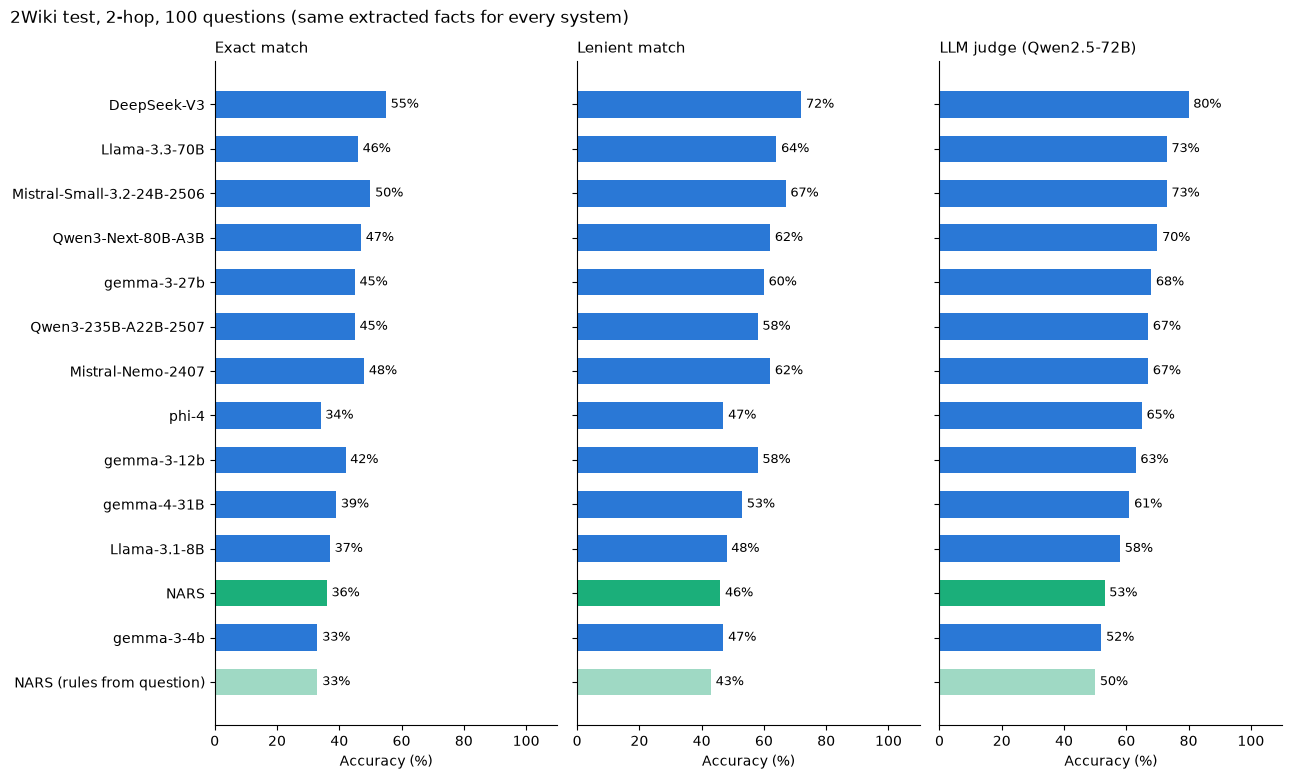

In [4]:
# ── Final report: everything that has been run for these settings, on all three metrics ──────────
def load(name):
    path = f"{RUN_DIR}/{name}"
    return {r["index"]: r for r in map(json.loads, open(path))} if os.path.exists(path) else {}


nars_runs, baseline_runs = load("nars.jsonl"), load("baselines.jsonl")
results, costs = {}, {}  # system name -> {question index: record with exact / lenient / judge}
if nars_runs:
    results["NARS"], costs["NARS"] = nars_runs, sum(r["cost"] for r in nars_runs.values())
    # NARS counting only answers whose rules start from the question (no hop filled in by the 70B): the number
    # that shows what NARS itself contributes. Same run, so the cost is not counted twice.
    results["NARS (rules from question)"] = {i: {**r, **{m: r[m] and r.get("from_question", False) for m in METRICS}}
                                             for i, r in nars_runs.items()}
    costs["NARS (rules from question)"] = 0.0
if baseline_runs:
    for name in next(iter(baseline_runs.values()))["answers"]:
        results[name] = {i: r["answers"][name] for i, r in baseline_runs.items()}
        costs[name] = sum(a["cost"] for a in results[name].values())
assert results, f"Nothing to report yet: run the NARS or the baselines cell first ({RUN_DIR} is empty)."
assert all("judge" in r for s in results.values() for r in s.values()), \
    "Some saved results are from before the three metrics: rerun the NARS and baselines cells."
common = sorted(set.intersection(*(set(s) for s in results.values())))  # questions every system answered
n = len(common)
accuracy = {name: {m: 100 * sum(s[i][m] for i in common) / n for m in METRICS} for name, s in results.items()}
judge_cost = sum(r["judge_cost"] for r in [*nars_runs.values(), *baseline_runs.values()])

print(f"FINAL REPORT: {DATASET} {SPLIT}, {HOPS}-hop, {n} questions, ONA options {ONA_OPTIONS}, "
      f"every system reads the same extracted facts")
table = PrettyTable(["System", "Exact", "Lenient", "Judge", "Cost USD"])
for name in sorted(results, key=lambda s: accuracy[s]["judge"], reverse=True):
    table.add_row([name, *[f"{accuracy[name][m]:.1f}%" for m in METRICS], f"${costs[name]:.4f}"])
print(table)
print(f"Systems ${sum(costs.values()):.4f} + judge ${judge_cost:.4f} = total ${sum(costs.values()) + judge_cost:.4f}")
if nars_runs:
    print(f"NARS (rules from question) = the same NARS run, counting only answers whose rules start from the question's "
          f"own entities.\nONA's own top answer (no preference for the rules' bindings), lenient: "
          f"{100 * sum(nars_runs[i].get('ona_top_lenient', False) for i in common) / n:.1f}%")

if "NARS" in results and len(results) > 1:
    print("\nNARS vs EACH BASELINE (judge metric, questions)")
    overlap = PrettyTable(["Baseline", "Both right", "Only NARS", "Only baseline", "Neither"])
    nr = {i: results["NARS"][i]["judge"] for i in common}
    for name, s in results.items():
        if not name.startswith("NARS"):
            b = {i: s[i]["judge"] for i in common}
            overlap.add_row([name, sum(nr[i] and b[i] for i in common), sum(nr[i] and not b[i] for i in common),
                             sum(b[i] and not nr[i] for i in common), sum(not b[i] and not nr[i] for i in common)])
    print(overlap)
    stages = Counter(nars_runs[i]["lost_at"] for i in common)
    print("Where NARS lost the answer:", ", ".join(f"{k} {v}" for k, v in stages.most_common()))

if "NARS" in results:
    print()
    repair_audit([nars_runs[i] for i in common])

# Judge-only flips: answers the lenient match rejected but the judge accepted. Check these by hand.
gold = {i: (nars_runs.get(i) or baseline_runs.get(i))["gold"] for i in common}
flips = PrettyTable(["System", "Q", "Gold", "Answer"])
flips.max_width = 40
for name in [s for s in results if s != "NARS (rules from question)"]:
    for i in common:
        if results[name][i]["judge"] and not results[name][i]["lenient"]:
            flips.add_row([name, i, gold[i], results[name][i]["answer"]])
print(f"\nJUDGE-ONLY FLIPS ({len(flips.rows)} answers only the judge accepted; check them by hand)")
print(flips)

# Chart: one panel per metric, same system order everywhere (sorted by the judge metric), NARS highlighted.
order = sorted(results, key=lambda s: accuracy[s]["judge"])
titles = {"exact": "Exact match", "lenient": "Lenient match", "judge": f"LLM judge ({label(JUDGE_MODEL)})"}
fig, axes = plt.subplots(1, 3, figsize=(13, 0.45 * len(order) + 1.6), sharey=True)
for ax, m in zip(axes, METRICS):
    ax.barh(order, [accuracy[s][m] for s in order], height=0.6,
            color=["#1baf7a" if s == "NARS" else "#9fd9c4" if s.startswith("NARS") else "#2a78d6" for s in order])
    for y, s in enumerate(order):
        ax.text(accuracy[s][m] + 1.5, y, f"{accuracy[s][m]:.0f}%", va="center", fontsize=9)
    ax.set_xlim(0, 110)
    ax.set_title(titles[m], fontsize=11, loc="left")
    ax.set_xlabel("Accuracy (%)")
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle(f"{DATASET} {SPLIT}, {HOPS}-hop, {n} questions (same extracted facts for every system)", x=0.01, ha="left")
fig.tight_layout()
fig.savefig(f"{RUN_DIR}/report.png", dpi=200)
plt.show()